# Stage 1 findings

Out-of-sample evaluation of the research core: S&P 500, daily data, 5-day forward return relative to SPY.

Run `uv run python research/stage1.py` first; this notebook only reads `data/results/` and reruns cheap backtest sensitivities. Everything here is walk-forward and stops before the hold-out (from 2024-11-01), which stays untouched until the final evaluation.

> Research and learning tool. Not investment advice.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import polars as pl

from quant_core.backtest import BacktestConfig, daily_returns, equity_curve, performance_summary, run_backtest, yearly_returns
from quant_core.validation import ExperimentLog, monthly_ic

ROOT = Path.cwd().parent if Path.cwd().name == 'research' else Path.cwd()
RESULTS = ROOT / 'data' / 'results'
MODELS = ['momentum_12_1', 'reversal_5', 'combo', 'ridge', 'lgbm', 'ridge_lgbm']
summary = json.loads((RESULTS / 'summary.json').read_text())
panel = pl.read_parquet(RESULTS / 'panel.parquet')
ic = {m: pl.read_parquet(RESULTS / f'ic_{m}.parquet') for m in MODELS}
bt = {m: pl.read_parquet(RESULTS / f'backtest_{m}.parquet') for m in MODELS}
pl.Config.set_tbl_rows(30); pl.Config.set_float_precision(4); pl.Config.set_tbl_width_chars(140)
plt.rcParams['figure.figsize'] = (11, 4)

## Data

In [2]:
print(f"{panel['ticker'].n_unique()} tickers, {panel['date'].n_unique()} dates, "
      f"{panel['date'].min()} .. {panel['date'].max()}")
panel.group_by(year=pl.col('date').dt.year()).agg(tickers=pl.col('ticker').n_unique()).sort('year').transpose(include_header=True)

503 tickers, 3978 dates, 2011-01-03 .. 2026-10-27


column,column_0,column_1,column_2,column_3,column_4,column_5,column_6,column_7,column_8,column_9,column_10,column_11,column_12,column_13,column_14,column_15
str,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64
"""year""",2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
"""tickers""",435,442,452,457,464,469,472,476,482,487,491,493,495,498,500,503


Universe is today's S&P 500 list, so earlier years contain only survivors and miss companies that were dropped or delisted. That biases long-side returns upwards and makes the backtest optimistic.

## Signal quality: information coefficient

IC = Spearman correlation between score and realised 5-day relative return, per date.

In [3]:
pl.DataFrame([{'model': m, **summary[m]['ic']} for m in MODELS]).sort('mean_ic', descending=True)

model,mean_ic,ic_std,ic_ir,ic_t,pct_positive_months,n_dates
str,f64,f64,f64,f64,f64,i64
"""combo""",0.0157,0.1956,0.0802,1.8669,0.6154,2708
"""ridge_lgbm""",0.0152,0.1605,0.0945,2.1995,0.5923,2708
"""lgbm""",0.0143,0.1208,0.1186,2.7607,0.6462,2708
"""reversal_5""",0.0142,0.1758,0.0806,1.8757,0.5923,2708
"""ridge""",0.0132,0.1768,0.0745,1.7349,0.5615,2708
"""momentum_12_1""",0.0103,0.2287,0.0452,1.0516,0.5308,2708


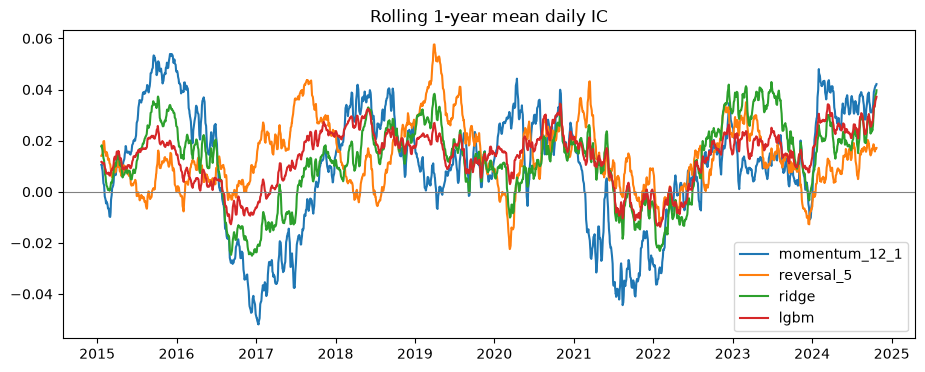

In [4]:
fig, ax = plt.subplots()
for m in ['momentum_12_1', 'reversal_5', 'ridge', 'lgbm']:
    s = ic[m].with_columns(roll=pl.col('ic').rolling_mean(252))
    ax.plot(s['date'], s['roll'], label=m)
ax.axhline(0, color='grey', lw=0.8)
ax.set_title('Rolling 1-year mean daily IC'); ax.legend(); plt.show()

In [5]:
pl.concat([
    ic[m].group_by(year=pl.col('date').dt.year()).agg(pl.col('ic').mean().alias(m)).sort('year').drop('year') if i else
    ic[m].group_by(year=pl.col('date').dt.year()).agg(pl.col('ic').mean().alias(m)).sort('year')
    for i, m in enumerate(MODELS)
], how='horizontal')

year,momentum_12_1,reversal_5,combo,ridge,lgbm,ridge_lgbm
i32,f64,f64,f64,f64,f64,f64
2014,0.0035,0.0191,0.0177,0.0101,0.0099,0.0106
2015,0.0470,0.0002,0.0362,0.0257,0.0145,0.0235
2016,-0.0479,0.0110,-0.0247,-0.0237,-0.0061,-0.0174
2017,0.0137,0.0236,0.0204,0.0124,0.0229,0.0196
2018,0.0175,0.0260,0.0239,0.0217,0.0172,0.0216
2019,0.0125,0.0079,0.0125,0.0083,0.0151,0.0136
2020,0.0212,0.0203,0.0284,0.0194,0.0214,0.0227
2021,-0.0284,0.0082,-0.0172,-0.0053,-0.0003,-0.0034
2022,0.0261,0.0217,0.0269,0.0313,0.0149,0.0246


## Long/short backtest

Long top 10%, short bottom 10%, equal weights, rebalanced every 5 days, traded at the close one day after the signal. Costs: 1 bp commission + 5 bp slippage per unit of turnover. Each side sums to 1, so returns are the long-short spread.

In [6]:
rows = []
for m in MODELS:
    for kind in ('gross', 'net'):
        s = summary[m][kind]
        rows.append({'model': m, 'kind': kind, **{k: s[k] for k in ('cagr', 'volatility', 'sharpe', 'sortino', 'max_drawdown', 'calmar', 'annual_turnover', 'hit_rate')}})
pl.DataFrame(rows)

model,kind,cagr,volatility,sharpe,sortino,max_drawdown,calmar,annual_turnover,hit_rate
str,str,f64,f64,f64,f64,f64,f64,f64,f64
"""momentum_12_1""","""gross""",-0.0221,0.2394,0.0284,0.0372,-0.5531,-0.0400,28.1222,0.5293
"""momentum_12_1""","""net""",-0.0385,0.2395,-0.0420,-0.0549,-0.6077,-0.0634,28.1222,0.5271
"""reversal_5""","""gross""",0.0517,0.2050,0.3480,0.5265,-0.5198,0.0995,174.5048,0.5035
"""reversal_5""","""net""",-0.0529,0.2052,-0.1625,-0.2405,-0.6040,-0.0875,174.5048,0.4799
"""combo""","""gross""",0.0240,0.2045,0.2191,0.3013,-0.4465,0.0537,142.5578,0.5234
"""combo""","""net""",-0.0600,0.2049,-0.1988,-0.2695,-0.6070,-0.0989,142.5578,0.5009
"""ridge""","""gross""",0.0692,0.1881,0.4496,0.6519,-0.3571,0.1937,118.9415,0.5249
"""ridge""","""net""",-0.0045,0.1883,0.0702,0.1003,-0.3960,-0.0114,118.9415,0.5079
"""lgbm""","""gross""",0.1019,0.1586,0.6908,1.0207,-0.3151,0.3233,124.1752,0.5312


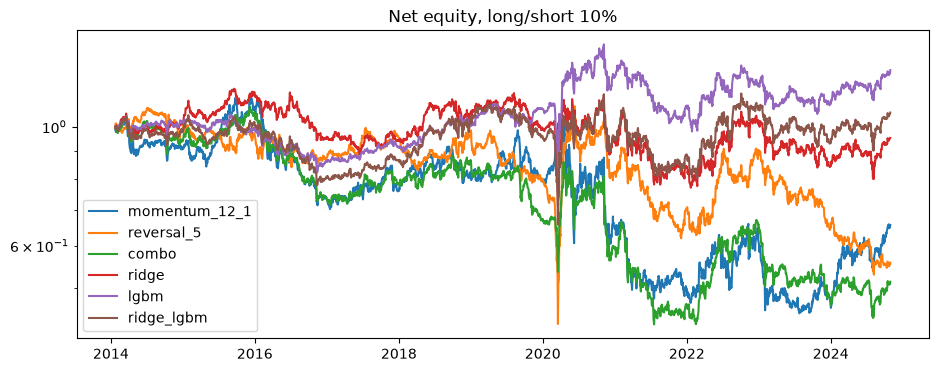

In [7]:
fig, ax = plt.subplots()
for m in MODELS:
    e = equity_curve(bt[m], 'net')
    ax.plot(e['date'], e['equity'], label=m)
ax.set_yscale('log'); ax.set_title('Net equity, long/short 10%'); ax.legend(); plt.show()

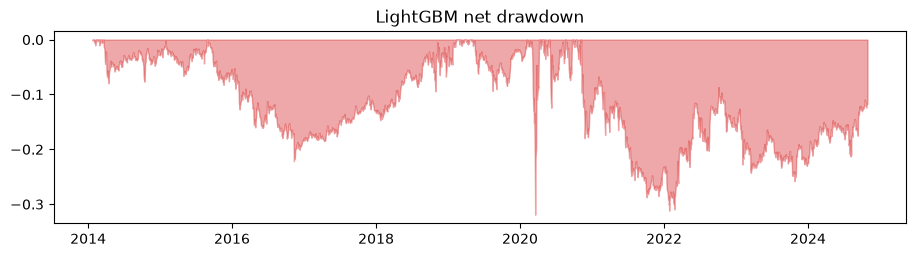

year,gross,net
i32,f64,f64
2014,0.0927,0.0155
2015,0.0486,-0.0238
2016,-0.0677,-0.1301
2017,0.1453,0.0596
2018,0.2129,0.1264
2019,0.1292,0.0464
2020,0.2358,0.1476
2021,-0.0463,-0.1152
2022,0.1852,0.1006


In [8]:
e = equity_curve(bt['lgbm'], 'net')
fig, ax = plt.subplots(figsize=(11, 2.5))
ax.fill_between(e['date'], e['drawdown'], 0, color='tab:red', alpha=0.4)
ax.set_title('LightGBM net drawdown'); plt.show()
yearly_returns(bt['lgbm'], 'gross').rename({'ret': 'gross'}).join(yearly_returns(bt['lgbm'], 'net').rename({'ret': 'net'}), on='year')

In [9]:
lgbm = bt['lgbm']
print('long leg  annualised:', f"{lgbm['long'].mean() * 252:+.2%}")
print('short leg annualised:', f"{lgbm['short'].mean() * 252:+.2%}")
print('cost drag annualised:', f"{lgbm['cost'].mean() * 252:.2%}")

long leg  annualised: +25.78%
short leg annualised: -14.83%
cost drag annualised: 7.45%


## Sensitivity (LightGBM scores)

These rerun the backtest with different trading parameters on the same out-of-sample scores. They describe the strategy, they are not used to pick a configuration.

In [10]:
scores = pl.read_parquet(RESULTS / 'scores_lgbm.parquet')
stocks = pl.read_parquet(ROOT / 'data' / 'raw' / 'prices.parquet').filter(pl.col('ticker') != 'SPY')
returns = daily_returns(stocks)

def run(**kw):
    cfg = BacktestConfig(**kw)
    s = performance_summary(run_backtest(scores, returns, cfg).daily)
    return kw | {k: s[k] for k in ('cagr', 'sharpe', 'max_drawdown', 'annual_turnover')}

pl.DataFrame([run(commission_bps=0, slippage_bps=c) for c in (0, 2, 5, 10, 20)])

commission_bps,slippage_bps,cagr,sharpe,max_drawdown,annual_turnover
i64,i64,f64,f64,f64,f64
0,0,0.1019,0.6908,-0.3151,124.1752
0,2,0.0749,0.5344,-0.3157,124.1752
0,5,0.0355,0.2994,-0.3180,124.1752
0,10,-0.0269,-0.0917,-0.4646,124.1752
0,20,-0.1408,-0.8613,-0.8247,124.1752


In [11]:
pl.DataFrame([run(rebalance_every=k) for k in (1, 5, 10, 21)])

rebalance_every,cagr,sharpe,max_drawdown,annual_turnover
i64,f64,f64,f64,f64
1,-0.1294,-0.7600,-0.7879,429.4134
5,0.0228,0.2210,-0.3191,124.1752
10,0.0200,0.2066,-0.3964,67.6900
21,0.0480,0.4032,-0.2757,35.1590


In [12]:
pl.DataFrame([run(fraction=f, weighting=w) for f in (0.05, 0.1, 0.2, 0.3) for w in ('equal', 'inverse_vol')])

fraction,weighting,cagr,sharpe,max_drawdown,annual_turnover
f64,str,f64,f64,f64,f64
0.0500,"""equal""",0.0229,0.2128,-0.4036,138.7547
0.0500,"""inverse_vol""",0.0252,0.2245,-0.3801,147.8229
0.1000,"""equal""",0.0228,0.2210,-0.3191,124.1752
0.1000,"""inverse_vol""",0.0129,0.1600,-0.3332,132.6998
0.2000,"""equal""",-0.0094,-0.0238,-0.3900,106.2800
0.2000,"""inverse_vol""",-0.0096,-0.0323,-0.3474,114.6244
0.3000,"""equal""",-0.0166,-0.1394,-0.3605,92.7925
0.3000,"""inverse_vol""",-0.0173,-0.1605,-0.3264,100.8297


## What LightGBM uses

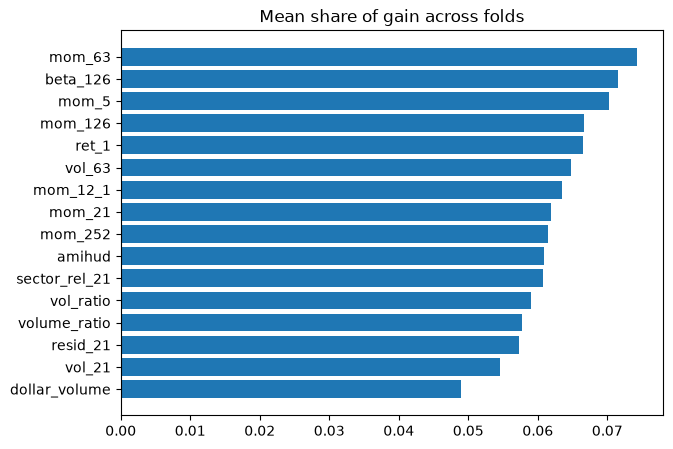

In [13]:
imp = pl.read_parquet(RESULTS / 'lgbm_importance.parquet')
imp = imp.with_columns(share=pl.col('gain') / pl.col('gain').sum().over('test_start'))
avg = imp.group_by('feature').agg(pl.col('share').mean()).sort('share')
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(avg['feature'], avg['share']); ax.set_title('Mean share of gain across folds'); plt.show()

## Multiple testing

In [14]:
log = ExperimentLog(ROOT / 'research' / 'experiments.jsonl')
print(f'{log.count()} evaluated variants recorded')
pl.DataFrame([{'time': e['time'], 'name': e['name'], 'mean_ic': e['metrics']['ic']['mean_ic'], 'net_sharpe': e['metrics']['net']['sharpe']} for e in log.entries()])

6 evaluated variants recorded


time,name,mean_ic,net_sharpe
str,str,f64,f64
"""2026-10-28T09:47:10+00:00""","""stage1/momentum_12_1""",0.0103,-0.0420
"""2026-10-28T09:47:11+00:00""","""stage1/reversal_5""",0.0142,-0.1625
"""2026-10-28T09:47:11+00:00""","""stage1/combo""",0.0157,-0.1988
"""2026-10-28T09:47:11+00:00""","""stage1/ridge""",0.0132,0.0702
"""2026-10-28T09:47:11+00:00""","""stage1/lgbm""",0.0143,0.2210
"""2026-10-28T09:47:12+00:00""","""stage1/ridge_lgbm""",0.0152,0.1232


## Findings

Run of 2026-10-28: prices to 2026-10-27, 43 expanding-window folds (quarterly retrain), out-of-sample
test period 2014-01-22 to 2024-10-23. The hold-out from 2024-11-01 was not used.

1. **There is a signal, and it is weak.** Mean daily IC is 0.010 to 0.016 for every model. LightGBM does not
   have the highest mean IC (the momentum + reversal combo baseline has), but it has the lowest IC
   volatility: IC IR 0.12, positive in 65% of months, overlap-adjusted t about 2.8. Ridge is no better than
   the simple baselines.
2. **Costs decide the outcome.** LightGBM long/short 10% earns 10.2% a year gross (Sharpe 0.69) and 2.3% net
   (Sharpe 0.22) at 6 bp per unit of turnover. Turnover is about 124x a year, a cost drag of about 7.5% a
   year; break-even is around 9 bp. Every baseline loses money after costs: 5-day reversal goes from +5.2%
   gross to -5.3% net.
3. **Trading less helps more than modelling more.** Monthly rebalancing of the same scores gives a net Sharpe
   of 0.40 against 0.22 weekly; daily rebalancing is ruinous. Concentrated books (top/bottom 5-10%) beat wide
   ones (20-30%), inverse-volatility weights do not help.
4. **Results depend on the regime.** 2016, 2021 and 2023 are losing years, matching momentum reversals;
   2018, 2020 and 2024 are strong. Drawdowns reach 32% net for LightGBM and about 60% for the baselines.
5. **LightGBM spreads its gain across features.** Medium-term momentum, beta, short-term reversal and
   volatility lead with 6-7% of gain each; no single feature dominates.

### Caveats

- Survivorship bias: the universe is today's index, so the ticker count grows from 435 in 2011 to 503.
  The long leg (+25.8% a year) is helped by this; the short leg returns -14.8% a year. The book is
  dollar-neutral, not beta-neutral.
- The sensitivity tables reuse the same out-of-sample period. Picking the best row would be in-sample
  selection; they show how fragile the result is, nothing more.
- Six variants are recorded in `research/experiments.jsonl`. Any later variant adds to that count.

### Next steps

- Reduce turnover inside the strategy: score smoothing and a holding buffer, judged net of costs.
- Try the sector-relative target and beta-neutral weights.
- Evaluate on the hold-out only once, after the configuration is frozen.
